In [1]:
# Our standard numpy and matplotlib imports
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# Exponential distribution

We'll start with the exponential distribution, which has the following probability density function:

$${p(x) = \lambda e^{-\lambda x}}$$

Let's translate this into a Python function:

In [2]:
def exponential_pdf(x, lam):
    return lam * np.exp(-lam * x)

print(exponential_pdf(2, 0.5)) # Test the function

0.18393972058572117


To get an idea for what the exponential pdf looks like we'll plot it over the range $[0, 3]$ for several values of $\lambda$:

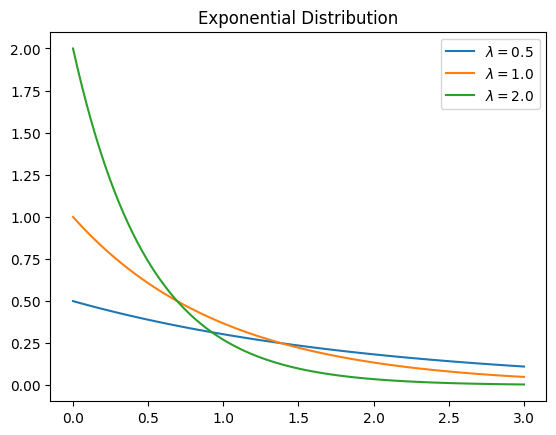

In [3]:
x = np.linspace(0, 3, 100)                       # Create 100 evenly spaced points b/w 0 and 3

for lam in [0.5, 1.0, 2.0]:
    y = exponential_pdf(x, lam)                  # Compute p(x) for each x
    plt.plot(x, y, label='$\lambda=%.1f$' % lam) # Plot with a label for each parameter
                                                 # ('$...$' ) allows for expressions in a label
plt.title('Exponential Distribution')
plt.legend()
plt.show()

**What about the cumulative distribution function?**

Recall that the CDF is defined as:

$${F(x) = \int_{-\infty}^x p(x) dx}$$

This is the *area under the curve* of the PDF function from $(-\infty, x]$ (or, equivalently: $(0, x]$ for the exponential distribution):



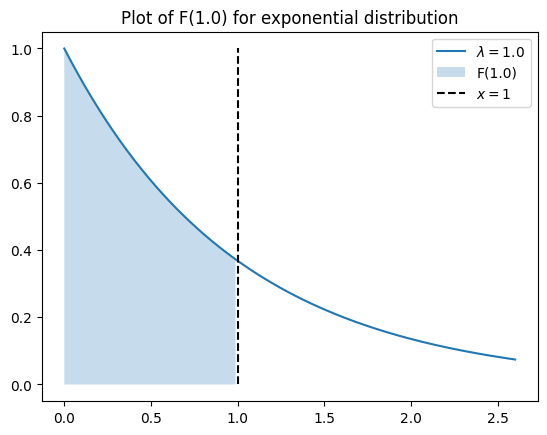

In [4]:
# Plot the pdf function as before, shading the CDF we're approximating
lam = 1.
x = np.linspace(0, 2 * 1.30, 130)
y = exponential_pdf(x, lam)
plt.plot(x, y, label='$\lambda=%.1f$' % lam)
plt.fill_between(x[:50], y[:50], np.zeros_like(y[:50]), alpha=0.25, label='F(1.0)')
plt.plot([1, 1], [0, 1], color='black', label='$x=1$', ls='--')

plt.title('Plot of F(1.0) for exponential distribution')
plt.legend()
plt.show()

For the exponential distribution, we can approximate this by breaking up [$0$, $x$] into $n$ discrete intervals of size $\left(\frac{x}{n}\right)$:

$${F(x) \approx \sum_{i=1}^{n} \left(\frac{x}{n}\right) p\left(i \cdot \frac{x}{n}\right)}$$

This is an example of a (right) Riemann sum. Let's use it to approximate $F(2)$ for the $\lambda=1$ case:

<>:23: SyntaxWarning: invalid escape sequence '\l'
<>:23: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_478/847789656.py:23: SyntaxWarning: invalid escape sequence '\l'
  plt.plot(x, y, label='$\lambda=%.1f$' % lam)


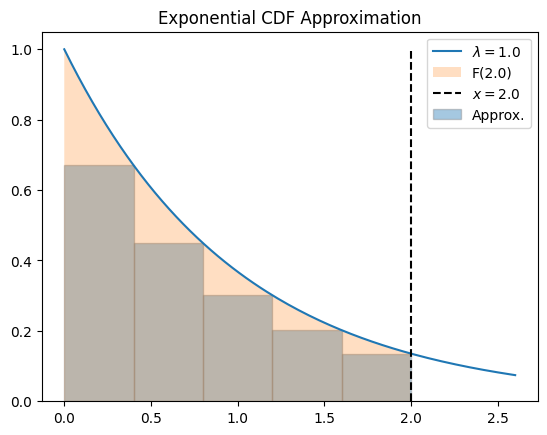

CDF approximation for F(2): 0.7032


In [18]:
def exponential_cdf_approximation(val, lam, n):
    ''' Plot and compute an approximation to F('val') for an exponential distribution
            with paratmeter 'lam' using 'n' intervals.
    '''

    # Compute the approximation:
    width = (val / n)                       # Width of each interval
    intervals = np.arange(1, n+1) * width   # Endpoint of each interval
    pdf = exponential_pdf(intervals, lam)   # PDF value at each interval edge

    F_x = np.sum(pdf * width)               # Get the approximation by summing the area under the
                                            #  curve at each interval


    # Make a nice plot (you can ignore this part):

    # Plot the area under the curve approximation
    plt.bar(intervals, pdf, align='edge', width=-width, alpha=0.4, linewidth=1.0, edgecolor='grey', label='Approx.')

    # Plot the pdf function as before, shading the CDF we're approximating
    x = np.linspace(0, val * 1.30, 130)
    y = exponential_pdf(x, lam)
    plt.plot(x, y, label='$\lambda=%.1f$' % lam)
    plt.fill_between(x[:100], y[:100], np.zeros_like(y[:100]), alpha=0.25, label='F(%.1f)' % val)

    # Mark the target value with a line
    plt.plot([val, val], [0, 1], color='black', label='$x=%.1f$' % val, ls='--')

    plt.title('Exponential CDF Approximation')
    plt.legend()
    plt.show()

    return F_x

# Approximate F(2) with 5 intervals
F_x = exponential_cdf_approximation(val=2.0, lam=1.0, n=5)
print('CDF approximation for F(2): %0.4f' % F_x)

The CDF for an exponential distribution is (Note: you can look up the PDF, CDF and other useful functions and values of distributions on Wikipedia):

$${F(x) = 1 - e^{-\lambda x}}$$

Let's make a function for that and compare it to our approximation:

In [19]:
def exponential_cdf(x, lam):
    return 1.0 - np.exp(-lam * x)

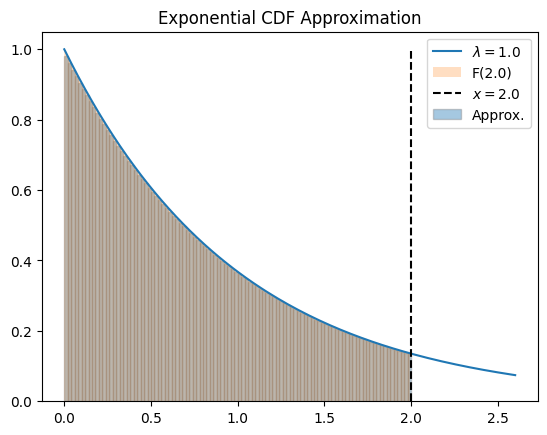

F(2.0) = 0.8647, approximated value: 0.8560, difference: 0.0086


In [20]:
val = 2.0 # Target value
lam = 1.0 # Exponential parameter
n = 100    # Number of intervals

true_cdf   = exponential_cdf(val, lam)
approx_cdf = exponential_cdf_approximation(val, lam, n)

print('F(%.1f) = %0.4f, approximated value: %0.4f, difference: %0.4f'\
    % (val, true_cdf, approx_cdf, abs(true_cdf - approx_cdf)))

We see that our approximation **underestimates** the true CDF. (If we computed the PDF at the left edges, we'd overestimate the CDF.) Additionally, we should see that as we increase the number of intervals, our approximation of the integral improves.

We can now plot both the PDF and CDF for the exponential distribution:

<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:10: SyntaxWarning: invalid escape sequence '\l'
<>:9: SyntaxWarning: invalid escape sequence '\l'
<>:10: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_478/3568944458.py:9: SyntaxWarning: invalid escape sequence '\l'
  ax1.plot(x, pdf, label='$\lambda=%.1f$' % lam)  # Plot with a label for each parameter
/tmp/ipykernel_478/3568944458.py:10: SyntaxWarning: invalid escape sequence '\l'
  ax2.plot(x, cdf, label='$\lambda=%.1f$' % lam)  # Plot with a label for each parameter


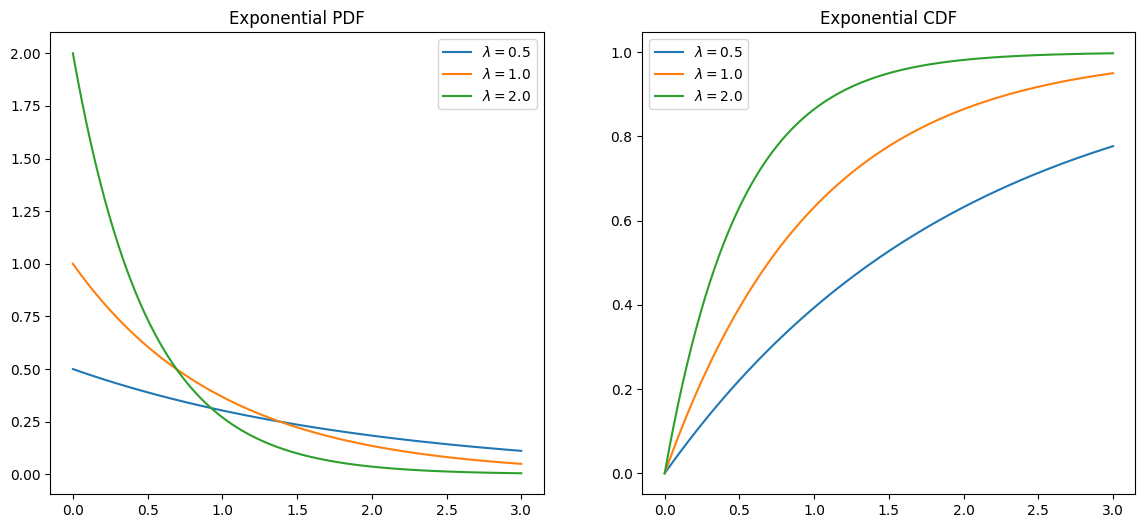

In [21]:
_, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6)) # Create 2 side-by-side plots

x = np.linspace(0, 3, 100)                          # Create x values for plotting

for lam in [0.5, 1.0, 2.0]:
    pdf = exponential_pdf(x, lam)                   # Compute p(x) for each x
    cdf = exponential_cdf(x, lam)                   # Compute F(x) for each x

    ax1.plot(x, pdf, label='$\lambda=%.1f$' % lam)  # Plot with a label for each parameter
    ax2.plot(x, cdf, label='$\lambda=%.1f$' % lam)  # Plot with a label for each parameter

ax1.set_title('Exponential PDF')
ax2.set_title('Exponential CDF')
ax1.legend(), ax2.legend()
plt.show()

# Normal Distribution

Another very useful distribution which is frequently used in probability and statistics is the Normal Distribution.
The PDF for the normal distribution is:

$${p(x) = \frac{1}{\sqrt{2\pi\sigma^2}} e^{\frac{(x-\mu)^2}{2\sigma^2}}}$$

We can translate this to Python as we did with the exponential distribution:

In [22]:
def normal_pdf(x, mu, sigma):
    pdf = 1 / np.sqrt(2 * np.pi * sigma**2)
    pdf *= np.exp(-(x - mu) ** 2 / (2 * sigma**2))
    return pdf

Let's try plotting a few different normal distributions over the range $[-4,4]$.

<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_478/752890538.py:5: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(x, y, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma)) # Plot with a label for each parameter


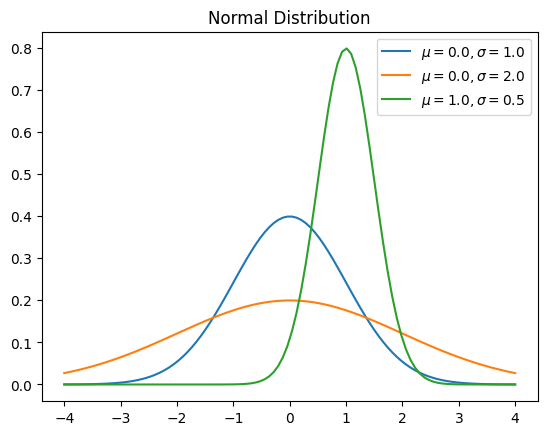

In [23]:
x = np.linspace(-4, 4, 100)                        # Create x values for plotting

for mu, sigma in [(0, 1), (0, 2), (1, 0.5)]:
    y = normal_pdf(x, mu, sigma)                  # Compute p(x) for each x
    plt.plot(x, y, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma)) # Plot with a label for each parameter

plt.title('Normal Distribution')
plt.legend()
plt.show()

**What about the cumulative distribution function?**

$${F(x) = \int_{-\infty}^x p(x)dx = \int_{-\infty}^x \frac{1}{\sqrt{2\pi\sigma^2}} e^{\frac{(x-\mu)^2}{2\sigma^2}} dx= ?}$$

The CDF function for the Normal distribution can't be expressed in closed form, so we need to approximate it! One option would be to write a discrete approximation function like we did with the exponential distribtion. However, Python provides an easier (and more accurate) alternative...

# Using the `scipy.stats` module

## Normal distribution

The SciPy module for probability and statistics contains many useful functions for working with distributions. For example, functions for the normal distribution are provided under `scipy.stats.norm`:

In [24]:
from scipy.stats import norm

The norm object gives us access to a PDF function like the one write just wrote. Importantly, it also has a CDF function, which uses an extremely accurate approximation of the normal CDF.

In [25]:
npdf = norm.pdf(0.5, loc=0, scale=1) # The pdf and cdf functions, note that scipy uses 'loc' and 'scale'
ncdf = norm.cdf(0.5, loc=0, scale=1) # to refer to the parameters of the distribution

# Equivalently, using the "frozen" RV object
X = norm(loc=0, scale=1)
npdf = X.pdf(0.5)
ncdf = X.cdf(0.5)

print('p(0.5) for a standard normal: %.4f' % npdf)
print('F(0.5) for a standard normal: %.4f' % ncdf)

p(0.5) for a standard normal: 0.3521
F(0.5) for a standard normal: 0.6915


We can now plot the normal pdf and cdf as before:

<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:9: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_478/2770138897.py:9: SyntaxWarning: invalid escape sequence '\m'
  ax1.plot(x, pdf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter
/tmp/ipykernel_478/2770138897.py:10: SyntaxWarning: invalid escape sequence '\m'
  ax2.plot(x, cdf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter


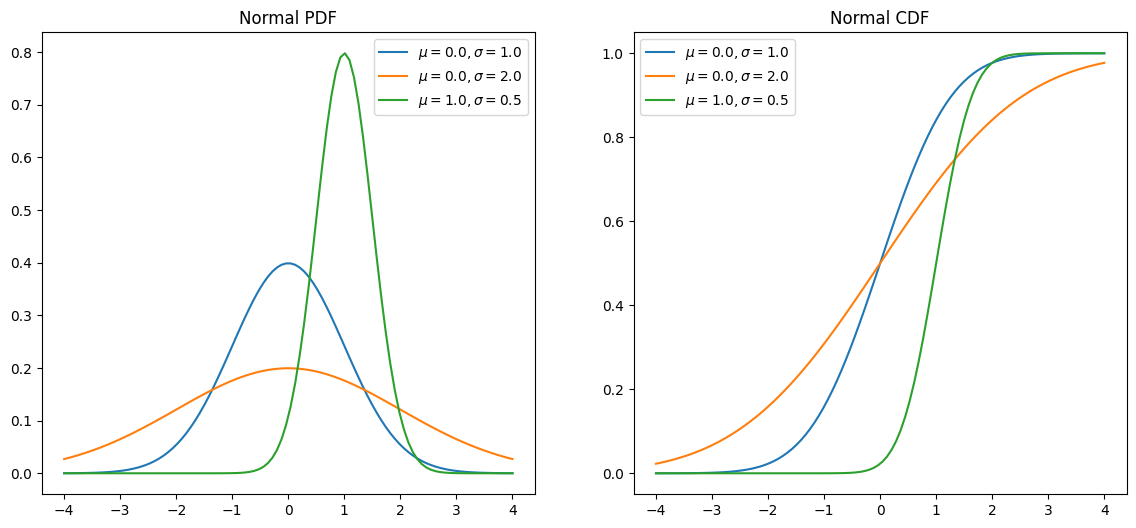

In [26]:
_, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6)) # Create 2 side-by-side plots

x = np.linspace(-4, 4, 100)                          # Create x values for plotting

for mu, sigma in [(0, 1), (0, 2), (1, 0.5)]:
    pdf = norm.pdf(x, loc=mu, scale=sigma)          # Compute p(x) for each x
    cdf = norm.cdf(x, loc=mu, scale=sigma)          # Compute F(x) for each x

    ax1.plot(x, pdf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter
    ax2.plot(x, cdf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter

ax1.set_title('Normal PDF')
ax2.set_title('Normal CDF')
ax1.legend(), ax2.legend()
plt.show()

Another useful function is the **norm.ppf**, which is the *inverse* of the CDF function [$F^{-1}(x)$]. In other words: if we have a value $a$ and we want to find $x$ such that $F(x) = a$, we'd use the ppf function. (PPF stands for percentile point function.)

In [27]:
ppf75 = norm.ppf(0.75, loc=0, scale=1) # Find the 75th percentile of a standard normal (F(x) = 0.75)

cdf = norm.cdf(ppf75, loc=0, scale=1)  # Verify that the cdf if 0.75 at that point

print('75th percentile: %.4f' % ppf75)
print('CDF verification: %.4f' % cdf)

75th percentile: 0.6745
CDF verification: 0.7500


The plot of the PPF function is just the CDF function with the axes switched:


<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_478/2899784723.py:10: SyntaxWarning: invalid escape sequence '\m'
  ax1.plot(x_cdf, cdf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter
/tmp/ipykernel_478/2899784723.py:11: SyntaxWarning: invalid escape sequence '\m'
  ax2.plot(x_ppf, ppf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter


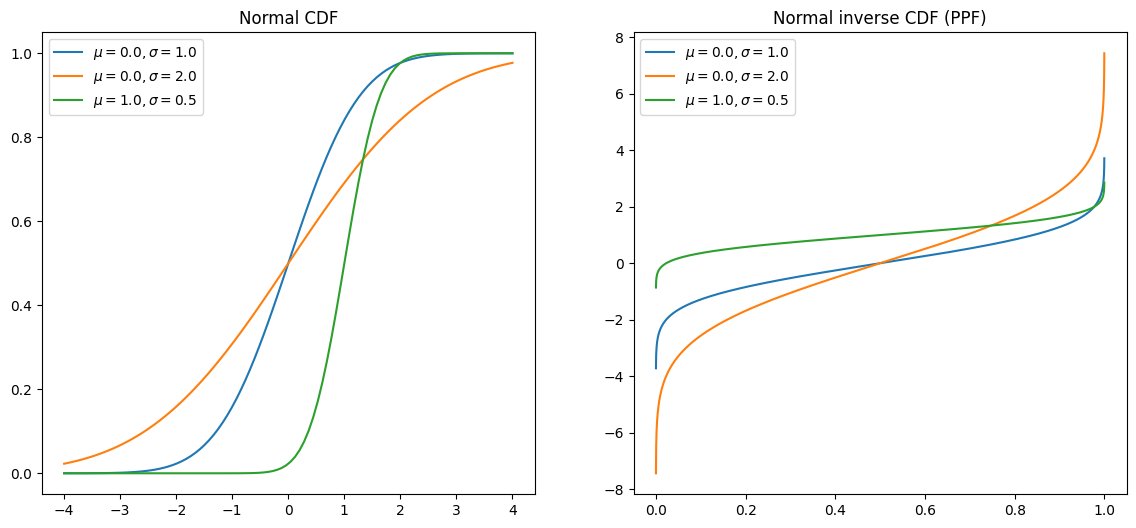

In [28]:
_, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6)) # Create 2 side-by-side plots

x_cdf = np.linspace(-4, 4, 100)                     # Create x values for plotting cdf
x_ppf = np.linspace(0., 1, 10000)                   # Create x values for plotting ppf

for mu, sigma in [(0, 1), (0, 2), (1, 0.5)]:
    cdf = norm.cdf(x_cdf, loc=mu, scale=sigma)          # Compute p(x) for each x
    ppf = norm.ppf(x_ppf, loc=mu, scale=sigma)          # Compute F(x) for each x

    ax1.plot(x_cdf, cdf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter
    ax2.plot(x_ppf, ppf, label='$\mu=%.1f, \sigma=%.1f$' % (mu, sigma))  # Plot with a label for each parameter

ax1.set_title('Normal CDF')
ax2.set_title('Normal inverse CDF (PPF)')
ax1.legend(), ax2.legend()
plt.show()

The `stats` module also allows us to draw samples from a given distribution using the rvs function:

In [29]:
print(norm.rvs(loc=0, scale=1, size=10)) # Draw 10 samples from a standard normal

[-0.71715489 -0.13933268  2.20834363 -0.76218387 -0.33089243  1.22914648
 -0.01365043 -0.08110579  0.91124898 -1.98937637]


Let's check that the mean and standard deviation of a set of samples match our parameters ($\mu=0, \sigma=1$):

In [33]:
nsamples = 10000
samples = norm.rvs(loc=0, scale=1, size=nsamples) # Draw a set of samples from the distribution

print('Sample mean: %.4f' % np.mean(samples))
print('Sample standard deviation: %.4f' % np.std(samples))

Sample mean: -0.0035
Sample standard deviation: 0.9993


We can also verify that our random samples are actually distributed as we'd expect by plotting a histogram of their values:

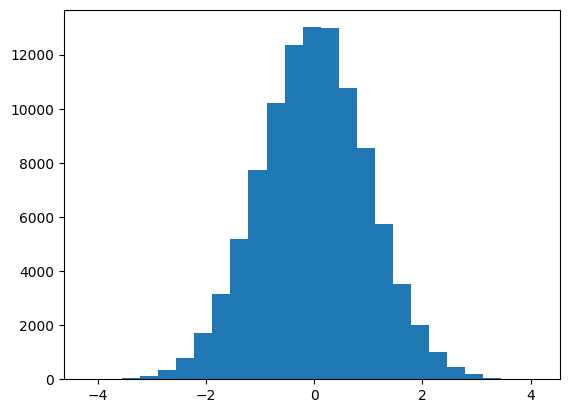

In [34]:
plt.hist(samples, bins=25) # Plot the histogram of the samples we drew
plt.show()

If we compare this histogram to the true pdf, we should see that it's pretty close!

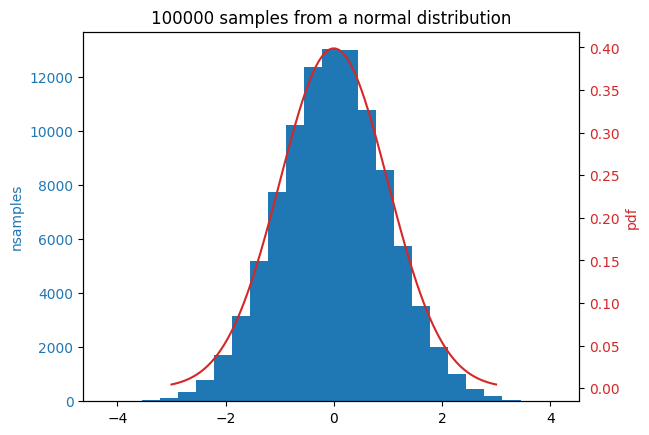

In [35]:
plt.hist(samples, bins=25, color='tab:blue') # Plot the histogram of the samples we drew

ax1 = plt.gca()                              # Gets a handle to the current plot
ax2 = ax1.twinx()                            # Instantiate a second axes that shares the same x-axis

# Plot the pdf for comparison
x = np.linspace(-3, 3, 100)
pdf = norm.pdf(x, loc=0, scale=1)
ax2.plot(x, pdf, color='tab:red')

# Format the plot
ax1.set_ylabel('nsamples', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.set_ylabel('pdf', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_title('%d samples from a normal distribution' % nsamples)

plt.show()

### Examples

Suppose $X \sim N(\mu=15, \sigma^2=3^2)$. Use the `stats` module to compute:
1. $P(X > 10)$
2. $P(5 < X < 10)$
3. $P(5 \leq X \leq 10)$
4. Keeping the standard deviation fixed at $\sigma = 3$, what should the mean be, so that only 5% of the population of $X$ have values over 20? *Hint: $Z = \frac{X-\mu}{\sigma}$, where $Z \sim N(0, 1)$*.

In [37]:
# Answer Here

$\mu = X - \sigma Z$

$\sigma = 3$

$X = 20$

$Z = \Phi^{-1}(0.95)$

$\rightarrow \mu = 20 - 3 \cdot  \Phi^{-1}(0.95)$


We will use the iris dataset to train a Gaussian naive Bayes classifier.  The iris dataset is a popular dataset used in teaching machine learning, probability and statistics.  For more details about the dataset: https://archive.ics.uci.edu/ml/datasets/iris

In [ ]:
# Load data
data = np.loadtxt('iris.txt', delimiter=',')

# Ignore third class
labels = data[:, -1]
data = data[labels != 2]

# Split into train and test sets
N = data.shape[0]
rand = np.random.permutation(np.arange(N))
split = int(N*0.8)
train_idx, test_idx = rand[:split], rand[split:]
train_data = data[train_idx]
test_data = data[test_idx]
trainFeat, trainLabels = train_data[:, :-1], train_data[:, -1]
testFeat, testLabels = test_data[:, :-1], test_data[:, -1]
M = trainFeat.shape[1]

# Split training data into two separate classes
trainFeat0 = trainFeat[trainLabels == 0]
trainFeat1 = trainFeat[trainLabels == 1]

# Estimate mean of Gaussian f_X|Y(x_ij | y_i)
# muhat[0,j] equals the mean of X_ij given Y_i=0
# muhat[1,j] equals the mean of X_ij given Y_i=1
muhat = np.zeros((2,M))
muhat[0] = np.mean(trainFeat0, axis=0)
muhat[1] = np.mean(trainFeat1, axis=0)

Set the means $\mu_{1j}, \mu_{0j}$ to match their empirical distributions on the training set (as computed above) and assume $\sigma_{0j}^2=\sigma_{1j}^2 = 1$. Use `scipy.stats.norm.logpdf` to compute on the **test** data:
$$\ln f_{X|Y}(x_i|1) = \sum_{j=1}^M \ln N(x_{ij} | \mu_{1j}, \sigma^2_{1j})$$
$$\ln f_{X|Y}(x_i|0) = \sum_{j=1}^M \ln N(x_{ij} | \mu_{0j}, \sigma^2_{0j})$$

In [ ]:
loglik0 = norm.logpdf(testFeat, loc=muhat[0], scale=1).sum(axis=1)
loglik1 = norm.logpdf(testFeat, loc=muhat[1], scale=1).sum(axis=1)

Assuming equal priors $P_Y(1)=P_Y(0)=0.5$, write code that predicts $Y_i = 1$ on the **test** data iff:
$$\ln p_Y(1) + \ln f_{X|Y}(x_i|1) > \ln p_Y(1) + \ln f_{X|Y}(x_i|1)$$

In [ ]:
p0 = np.log(0.5) + loglik0
p1 = np.log(0.5) + loglik1
yHat = p1 > p0

Finally, compute the accuracy of your predictions against the **true test labels**.

In [ ]:
print(np.mean(yHat == testLabels))

1.0


## Exponential distribution

The scipy.stats module also includes the exponential distribution. However, it uses a $scale$ parameter instead of $\lambda$, where $scale=\frac{1}{\lambda}$

In [ ]:
from scipy.stats import expon

lam = 2.
scale = 1. / lam                          # Get the scale parameter from lam

epdf = expon.pdf(0.5, scale=scale)        # Compute pdf function
ecdf = expon.cdf(0.5, scale=scale)        # Compute cdf function

samples = expon.rvs(scale=scale, size=10) # Draw a set of 10 samples from the distribution

print('p(0.5) = %.4f' % epdf)
print('F(0.5) = %.4f' % ecdf)

print('\n10 Random samples:')
print(samples)

p(0.5) = 0.7358
F(0.5) = 0.6321

10 Random samples:
[0.24978702 0.36485239 0.63594832 0.12291918 0.09742205 0.04583185
 0.07535593 0.00913737 0.73255647 0.57110204]


As with the normal distribution, we can verify our pdf with a histogram:

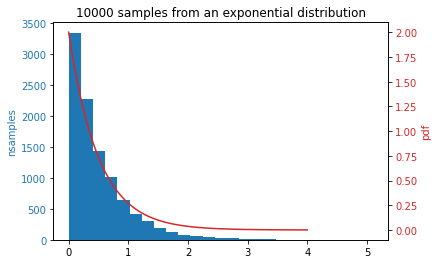

In [ ]:
nsamples = 10000
samples = expon.rvs(scale=scale, size=nsamples) # Draw a set of samples from the distribution

plt.hist(samples, bins=25, color='tab:blue')    # Plot the histogram of the samples we drew

ax1 = plt.gca()                                 # Gets a handle to the current plot
ax2 = ax1.twinx()                               # Instantiate a second axes that shares the same x-axis

# Plot the pdf for comparison
x = np.linspace(0, 4, 100)
pdf = expon.pdf(x, scale=scale)
ax2.plot(x, pdf, color='tab:red')

# Format the plot
ax1.set_ylabel('nsamples', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax2.set_ylabel('pdf', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')
ax2.set_title('%d samples from an exponential distribution' % nsamples)

plt.show()

# Discrete approximations of moments

Let's go back to the scenerio where we know a probability density function, but we don't know how to integrate it. We saw how to estimate the CDF using a discrete approximation. How about computing the moments of the distribution like the expectation:

$${E[X] = \int_{-\infty}^{\infty} x \cdot p(x)} dx = ?$$

As an example we'll use the **beta distribution**, which is defined on [0,1].

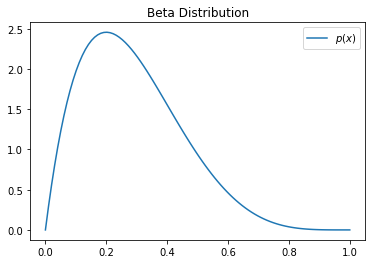

In [ ]:
from scipy.stats import beta     # Import the beta distribution from scipy

x = np.linspace(0, 1, 100)
y = beta.pdf(x, a=2, b=5)        # We'll use the arguments 2 and 5, but don't worry about what these mean

plt.plot(x, y, label='$p(x)$')

plt.title('Beta Distribution')
plt.legend()
plt.show()

**How can we find the expectation (mean) of this distribution?**


We can use a similar approximation as before, we'll break up [$0$, $1$] into $n$ discrete intervals of size $\left(\frac{1}{n}\right)$:

$${E[X] \approx \sum_{i=1}^{n} \left(\frac{1}{n}\right) \left(i \cdot \frac{1}{n}\right)  p\left(i \cdot \frac{1}{n}\right)}$$

Notice that we now multiply each interval by $\left(i \cdot \frac{1}{n}\right)$, as we're replacing $x$ with $\left(i \cdot \frac{1}{n}\right)$.

**What about the variance?**

We can similarly approximate $E[X^2]$ using the same approach, but multiplying by $\left(i \cdot \frac{1}{n}\right)^2$:

$${E[X^2] \approx \sum_{i=1}^{n} \left(\frac{1}{n}\right)  \left(i \cdot \frac{1}{n}\right)^2 p\left(i \cdot \frac{1}{n}\right)}$$

Therefore we can approximate the variance using the formula:

$${Var[X] = E[X^2] - E[X]^2}$$

Let's try this out with our new pdf:

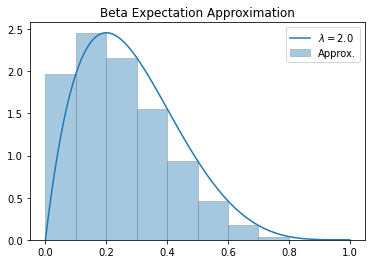

Approximated expectation: 0.286
Approximated variance: 0.026


In [ ]:
def expectation_approximation(n, power=1, plot=True):
    ''' Plot and compute an approximation to F('val') for an exponential distribution
            with paratmeter 'lam' using 'n' intervals.
    '''
    # Compute the approximation:
    width = (1. / n)                        # Width of each interval
    intervals = np.arange(1, n+1) * width   # Endpoint of each interval

    pdf =  beta.pdf(intervals, a=2, b=5)    # PDF value at each interval edge
    E_x = np.sum(intervals ** power * pdf * width)   # Get the approximation by summing the area under the
                                                     #  curve at each interval times the location of the interval

    # Make a nice plot (you can ignore this part):
    if plot:
        # Plot the area under the curve approximation
        plt.bar(intervals, pdf, align='edge', width=-width, alpha=0.4, linewidth=1.0, edgecolor='grey', label='Approx.')

        # Plot the pdf function as before, shading the CDF we're approximating
        x = np.linspace(0, 1, 100)
        y = beta.pdf(x, a=2, b=5)
        plt.plot(x, y, label='$\lambda=%.1f$' % lam)

        plt.title('Beta Expectation Approximation')
        plt.legend()
        plt.show()

    return E_x

E_x = expectation_approximation(10)                        # Approximate E[X]
E_x2 = expectation_approximation(10, power=2, plot=False)  # Approximate E[X^2]
var_x = E_x2 - E_x ** 2

print ('Approximated expectation: %.3f' % E_x)
print ('Approximated variance: %.3f' % var_x)


Since SciPy provides functions for the true mean and variance for the beta distribution, we can see how accurate our approximation was:

In [ ]:
E_x_true = beta.mean(a=2, b=5)
var_x_true = beta.var(a=2, b=5)

print('True expectation: %.3f' % (E_x_true))
print('True variance: %.3f' % (var_x_true))

True expectation: 0.286
True variance: 0.026


# Multivariate Normal Distributions

The multivariate normal distribution has the following probability density function:

$$p(\boldsymbol{x}) = \frac{1}{\sqrt{2\pi}|\Sigma|^{\frac{1}{2}}} e^{\frac{-1}{2}(\boldsymbol{x} - \boldsymbol{\mu})^T \Sigma^{-1} (\boldsymbol{x} - \boldsymbol{\mu})} $$

Lets start by defining a 2D multivariate normal and sampling from it.  Numpy has a built in function that can be used to sample from a multivariate normal that we could use or we could also use the Scipy random distributions to sample from the distribution as we did above for the exponential and univariate normal distributions.

In [ ]:
# Create a mean (0,0) with diagonal covariance matrixs
mean = np.array([0,0])
cov = np.eye(2)

# Draw 10 samples from the distribution using numpy
samples = np.random.multivariate_normal(mean, cov, size=(10,))
print(samples.shape)
print(samples)

# Using scipy
from scipy.stats import multivariate_normal

# create the random variable that represents the 2D distribution
rv = multivariate_normal(mean, cov)
samples = rv.rvs((10, ))
print(samples.shape)
print(samples)

(10, 2)
[[-0.21067054 -1.35480898]
 [-0.7155087  -0.69897566]
 [-0.15894715  1.76543389]
 [ 1.18770575  0.61006013]
 [ 0.39250699  0.10051519]
 [ 0.31792259 -1.73767201]
 [-1.77865823  1.06760568]
 [ 1.49374521  0.4602368 ]
 [-1.05167795  1.40419043]
 [-0.58891466  1.359977  ]]
(10, 2)
[[ 0.39341297  1.51672256]
 [ 0.88810265  0.91745764]
 [ 0.84480531 -1.75982193]
 [ 1.44912581 -0.29927389]
 [-0.56163088 -3.38205855]
 [-0.08710157 -0.65105059]
 [ 0.57058824  0.21669633]
 [-0.08224648  0.35187396]
 [ 0.7928302  -1.22669152]
 [-0.40895353  0.87136107]]


Scipy also allows us to evaluate the PDF of the multivariate normal at specific points:

In [ ]:
# Generate some values to evaluate the PDF at
x = np.random.uniform(-3, 3, size=(5, 2))

# PDF values
pdf = rv.pdf(x)
for i in range(values.shape[0]):
    print("{} has PDF value {}".format(values[i], pdf[i]))

[0.32008126 0.3104947 ] has PDF value 0.015089916574001935
[-0.58936845 -1.87316866] has PDF value 0.014372077990634361
[-1.87942096  0.40340308] has PDF value 0.015513413662439305
[ 1.60276874 -0.65054479] has PDF value 0.0169619025530862
[-1.60857659 -0.44864926] has PDF value 0.0548803084601176


Like before we can visualize the distribution using a histogram of random samples:

(-3.0, 3.0, -3.0, 3.0)

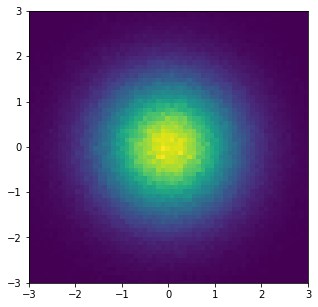

In [ ]:
# Draw many samples from the distribution
samples = rv.rvs((1000000,))

# Plot them using a 2D histogram since we have a 2D distributon
fig = plt.figure(figsize=(5,5)) # make the plot a square
_ = plt.hist2d(samples[:,0], samples[:,1], bins=100)
plt.axis([-3, 3,-3, 3]) # set the x and y axis of the plot

For 2D distributions we can also visualize by densely sampling the 2D space, evaluating the PDF at each point and rendering using a contour.

For higher dimensional distributions, you could marginalize out all but 2 dimensions and render those as rendering more dimensions makes visualization difficult.  Also as the number of dimensions increases, the computational cost of densely sampling the D space (where D is the number of dimensions) grows quickly (order of $O(N^D)$ where D is the number of dimensions and N is the density to sample with).

(-3.0, 3.0, -3.0, 3.0)

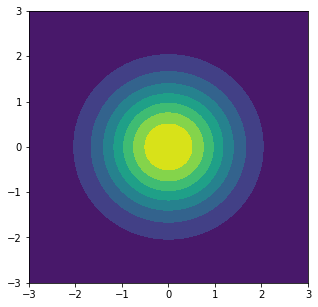

In [ ]:
# Create the dense grid over the 2D space
x = np.linspace(-3, 3, 100)
x, y = np.meshgrid(x, x)

# Evaluate the PDF
pos = np.empty(x.shape + (2,))
pos[:, :, 0] = x
pos[:, :, 1] = y
pdf = rv.pdf(pos)

# Plot in Guassian using a contour map.
fig = plt.figure(figsize=(5,5)) # make the plot a square
plt.contourf(x, y, pdf)
plt.axis([-3, 3,-3, 3])

Another example where the covariance is still diagonal but the values along the diagonals are not 1

(-3.0, 3.0, -3.0, 3.0)

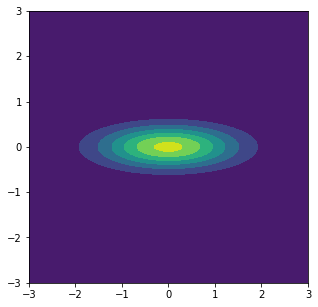

In [ ]:
# Diagonal covaraince but not all the same value
cov = np.asarray([[1.0, 0],[0, 0.1]])

# Evaluate the PDF
rv = multivariate_normal(mean, cov)
pdf = rv.pdf(pos)

# Plot in Guassian using a contour map.
fig = plt.figure(figsize=(5,5)) # make the plot a square
plt.contourf(x, y, pdf)
plt.axis([-3, 3,-3, 3])

Now that we can visualize multivariate normals, lets take a look at what happens if we have non diagonal covariance matrices.

(-3.0, 3.0, -3.0, 3.0)

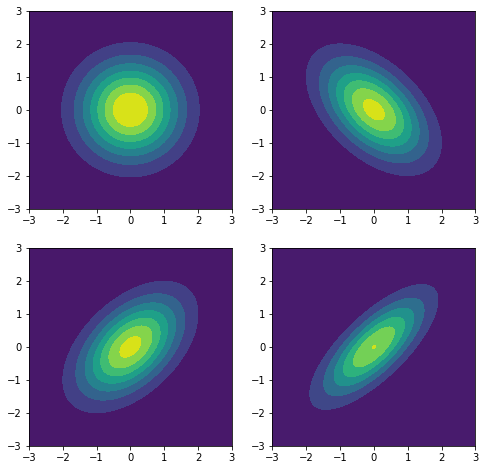

In [ ]:
cov1 = np.eye(2)
cov2 = np.asarray([[1, 0.5],[0.5, 1]])
cov3 = np.asarray([[1, -0.5],[-0.5, 1]])
cov4 = np.asarray([[1, 0.75],[0.75, 1]])

# Plot in Guassian using a contour map.
fig, axes = plt.subplots(2, 2,figsize=(8,8))
pdf = multivariate_normal(mean, cov1).pdf(pos)
axes[0,0].contourf(x, y, pdf)
axes[0,0].axis([-3, 3,-3, 3])

pdf = multivariate_normal(mean, cov2).pdf(pos)
axes[1,0].contourf(x, y, pdf)
axes[1,0].axis([-3, 3,-3, 3])

pdf = multivariate_normal(mean, cov3).pdf(pos)
axes[0,1].contourf(x, y, pdf)
axes[0,1].axis([-3, 3,-3, 3])

pdf = multivariate_normal(mean, cov4).pdf(pos)
axes[1,1].contourf(x, y, pdf)
axes[1,1].axis([-3, 3,-3, 3])

As can be seen from the plots above, having off diagonal elements in the covariance matrix changes the shape of the distribution.  In the 2D case, we see that the off diagonal entries in the covariance matrix skew the distribution.

We can also shift the mean around (though this is not as interesting as changing the covariance matrix)

(-3.0, 3.0, -3.0, 3.0)

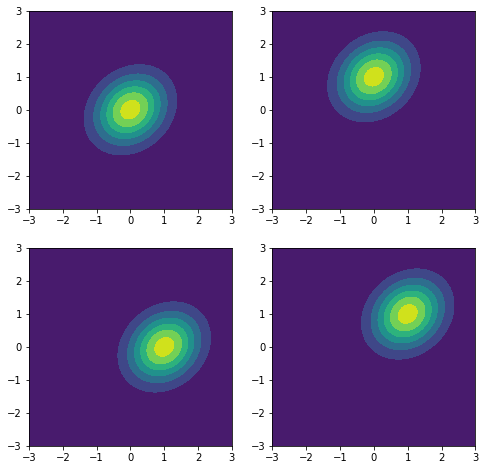

In [ ]:
cov = np.asarray([[0.5, 0.1],[0.1, 0.5]])

mean1 = np.asarray([0, 0])
mean2 = np.asarray([1, 0])
mean3 = np.asarray([0, 1])
mean4 = np.asarray([1, 1])

# Plot in Guassian using a contour map.
fig, axes = plt.subplots(2, 2,figsize=(8,8))
pdf = multivariate_normal(mean1, cov).pdf(pos)
axes[0,0].contourf(x, y, pdf)
axes[0,0].axis([-3, 3,-3, 3])

pdf = multivariate_normal(mean2, cov).pdf(pos)
axes[1,0].contourf(x, y, pdf)
axes[1,0].axis([-3, 3,-3, 3])

pdf = multivariate_normal(mean3, cov).pdf(pos)
axes[0,1].contourf(x, y, pdf)
axes[0,1].axis([-3, 3,-3, 3])

pdf = multivariate_normal(mean4, cov).pdf(pos)
axes[1,1].contourf(x, y, pdf)
axes[1,1].axis([-3, 3,-3, 3])

Changing the mean changes the center of the distribution but does not change the shape.   

## Estimating the Mean and Covariance of a Multivariate  Normal distribution from samples

Now say we have a bunch of data and we want to fit a multivariate normal distribution to that data such that the distribution models the data as best as possible.  

For the following example we will be fitting a 3D multivariate normal distribution to 3D data.

Let $\boldsymbol{x_i} = (x_{i, 0}, x_{i, 1}, x_{i, 2})$ be a single 3D data point from the dataset and assume we have $N$ data points.

We can approximate the mean (and covariance) of the multivariate normal distribution using the method of maximum likelihood estimation.  Below is how we estimate the mean and covariance of the distribution after solving the MLE problem for multivariate normal distributions (you can look this up online, we do not include the derivation here since it is a bit long).
$$\hat{\boldsymbol{\mu}} = \frac{1}{N}\sum_{i=1}^{N} \boldsymbol{x_i}$$

$$\hat{\Sigma} = \frac{1}{N}\sum_{i=1}^{N} (\boldsymbol{x_i} - \hat{\boldsymbol{\mu}})(\boldsymbol{x_i} - \hat{\boldsymbol{\mu}})^T\$$

First we need to create a dataset:

In [ ]:
# Create a distribution to generate data
mean = np.asarray([0, 1, 10])
cov = np.asarray([[1,0.5,0],[0.5,2,0.25],[0,0.25,3]])
data = np.random.multivariate_normal(mean, cov, size=(10000,))

print(data.shape)

(10000, 3)


Estimate the mean and covariance using the above equations.

In [ ]:
# Compute the mean
# Note: could also just use
#    mean_hat = np.mean(data,axis=0)
mean_hat = np.sum(data,axis=0) / data.shape[0]

# Compute the covariance
diff = data - np.reshape(mean_hat, (1, -1))
diff = np.reshape(diff, (diff.shape[0], -1, 1))
diff_transpose = np.transpose(diff, axes=[0, 2, 1])
cov_hat = np.mean(diff @ diff_transpose, axis=0 )

print("Mean:")
print("True", mean)
print("Estimate", mean_hat)
print("Mean L1 error", np.mean(np.abs(mean-mean_hat)))

print("-----------")
print("Covariance:")
print("True", cov)
print("Estimate", cov_hat)
print("Mean L1 error", np.mean(np.abs(cov-cov_hat)))

Mean:
True [ 0  1 10]
Estimate [9.05062218e-03 1.02080570e+00 9.97495698e+00]
Mean L1 error 0.018299779238878863
-----------
Covariance:
True [[1.   0.5  0.  ]
 [0.5  2.   0.25]
 [0.   0.25 3.  ]]
Estimate [[0.9990366  0.50746305 0.00456688]
 [0.50746305 2.03730276 0.24348352]
 [0.00456688 0.24348352 2.95861079]]
Mean L1 error 0.012972022331775433


As can be seen the estimated mean and covariance are pretty close to the true mean and covariance that the data was generated from!